<a href="https://colab.research.google.com/github/Sineth7077/project-aura/blob/main/notebooks/03_model_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project Aura 2.0 — Notebook 03: EfficientNet-B0 Training

**Goal:** Train and evaluate a real 10-class image classifier using CIFAR-10 and pretrained EfficientNet-B0.

This notebook is a genuine transfer-learning experiment. It:
- downloads CIFAR-10 (50,000 training images and 10,000 test images)
- creates separate training and validation transforms
- resizes images to 224 × 224 for EfficientNet-B0
- uses ImageNet pretrained weights
- trains the classifier head, then fine-tunes the final feature blocks
- tracks loss and accuracy
- saves the best validation checkpoint
- evaluates the selected model on the held-out test set

**Important:** CIFAR-10 is a classification benchmark. It is useful for validating Aura's training pipeline, but it is not the object-detection model used by the future live YOLO vision system.

Run cells from top to bottom. A GPU runtime is recommended.

## 1. Runtime and project setup

This notebook expects the verified repository at `/content/project-aura-verified`. If the Colab runtime has restarted, it clones the repository again. It deliberately stops if that directory exists but is not a valid checkout, rather than deleting or overwriting it.

In [1]:
from pathlib import Path
import os
import sys
import subprocess
import importlib

PROJECT_DIR = Path("/content/project-aura-verified")

if not PROJECT_DIR.exists():
    subprocess.run(
        ["git", "clone", "https://github.com/Sineth7077/project-aura.git", str(PROJECT_DIR)],
        check=True,
    )

if not (PROJECT_DIR / ".git").is_dir():
    raise RuntimeError(
        f"{PROJECT_DIR} exists but is not a valid Git checkout. "
        "Inspect it before replacing anything."
    )

if not (PROJECT_DIR / "src/core/config.py").is_file():
    raise FileNotFoundError("Expected src/core/config.py was not found in the repository.")

# Avoid importing src from an older/stale checkout in this Colab runtime.
for module_name in list(sys.modules):
    if module_name == "src" or module_name.startswith("src."):
        del sys.modules[module_name]

sys.path = [
    entry for entry in sys.path
    if not entry or Path(entry).resolve() != Path("/content/project-aura").resolve()
]
sys.path.insert(0, str(PROJECT_DIR))
os.chdir(PROJECT_DIR)
importlib.invalidate_caches()

import src
print("Project directory:", PROJECT_DIR)
print("Imported src from:", src.__file__)

Project directory: /content/project-aura-verified
Imported src from: /content/project-aura-verified/src/__init__.py


## 2. Imports and reproducibility

In [2]:
import json
import math
import random
import time
from copy import deepcopy

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from torchvision.models import EfficientNet_B0_Weights

from src.core.config import load_config

config = load_config()
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Deterministic behavior where practical; may slightly reduce performance.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Torchvision:", __import__("torchvision").__version__)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Aura config model:", config.vision.model_name)
print("Aura config input size:", config.vision.input_size)

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Device: cuda
GPU: Tesla T4
Aura config model: efficientnet_b0
Aura config input size: (224, 224)


## 3. Training settings

The values below use the repository configuration where appropriate. The validation split is taken only from CIFAR-10's official training set. The official test set remains untouched until final evaluation.

In [3]:
NUM_CLASSES = 10
IMAGE_SIZE = 224
BATCH_SIZE = int(config.vision.batch_size)
EPOCHS = int(config.vision.epochs)
INITIAL_HEAD_EPOCHS = min(3, max(1, EPOCHS // 3))
LEARNING_RATE_HEAD = float(config.vision.learning_rate)
LEARNING_RATE_FINETUNE = LEARNING_RATE_HEAD * 0.1
WEIGHT_DECAY = 1e-4
VALIDATION_FRACTION = 0.10
NUM_WORKERS = 2 if DEVICE.type == "cuda" else 0

DATA_DIR = PROJECT_DIR / "data" / "external"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
DATA_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

BEST_CHECKPOINT_PATH = CHECKPOINT_DIR / "efficientnet_b0_cifar10_best.pth"
LAST_CHECKPOINT_PATH = CHECKPOINT_DIR / "efficientnet_b0_cifar10_last.pth"

print("Classes:", NUM_CLASSES)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Head-only epochs:", INITIAL_HEAD_EPOCHS)
print("Data directory:", DATA_DIR)
print("Checkpoint directory:", CHECKPOINT_DIR)

Classes: 10
Batch size: 32
Epochs: 10
Head-only epochs: 3
Data directory: /content/project-aura-verified/data/external
Checkpoint directory: /content/project-aura-verified/checkpoints


## 4. CIFAR-10 transforms

EfficientNet-B0 expects 224 × 224 RGB inputs. The pretrained ImageNet weights also specify the normalization values used here. Training images receive light augmentation; validation and test images do not.

In [4]:
weights = EfficientNet_B0_Weights.DEFAULT
imagenet_mean = weights.transforms().mean
imagenet_std = weights.transforms().std

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std),
])

print("Image size:", IMAGE_SIZE)
print("ImageNet mean:", imagenet_mean)
print("ImageNet std:", imagenet_std)

Image size: 224
ImageNet mean: [0.485, 0.456, 0.406]
ImageNet std: [0.229, 0.224, 0.225]


## 5. Download CIFAR-10 and create train/validation/test sets

CIFAR-10 contains 50,000 training images and 10,000 official test images across 10 classes. We reserve 10% of the official training set for validation.

In [5]:
train_dataset_aug = datasets.CIFAR10(
    root=str(DATA_DIR), train=True, download=True, transform=train_transform
)
train_dataset_eval = datasets.CIFAR10(
    root=str(DATA_DIR), train=True, download=False, transform=eval_transform
)
test_dataset = datasets.CIFAR10(
    root=str(DATA_DIR), train=False, download=True, transform=eval_transform
)

class_names = train_dataset_aug.classes
num_total = len(train_dataset_aug)
num_val = int(num_total * VALIDATION_FRACTION)

generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(num_total, generator=generator).tolist()
val_indices = indices[:num_val]
train_indices = indices[num_val:]

train_dataset = Subset(train_dataset_aug, train_indices)
val_dataset = Subset(train_dataset_eval, val_indices)

print("Classes:", class_names)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

assert len(train_dataset) == 45000
assert len(val_dataset) == 5000
assert len(test_dataset) == 10000

100%|██████████| 170M/170M [07:18<00:00, 389kB/s]


Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Training images: 45000
Validation images: 5000
Test images: 10000


## 6. Create data loaders

In [6]:
loader_options = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": DEVICE.type == "cuda",
}
if NUM_WORKERS > 0:
    loader_options["persistent_workers"] = True

train_loader = DataLoader(
    train_dataset, shuffle=True, drop_last=False, **loader_options
)
val_loader = DataLoader(
    val_dataset, shuffle=False, drop_last=False, **loader_options
)
test_loader = DataLoader(
    test_dataset, shuffle=False, drop_last=False, **loader_options
)

images, labels = next(iter(train_loader))
print("Batch images:", tuple(images.shape))
print("Batch labels:", tuple(labels.shape))
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)
assert images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)

Batch images: (32, 3, 224, 224)
Batch labels: (32,)
Image dtype: torch.float32
Label dtype: torch.int64


## 7. Inspect a sample batch

The display reverses ImageNet normalization for visualization only. It does not change the tensors used for training.

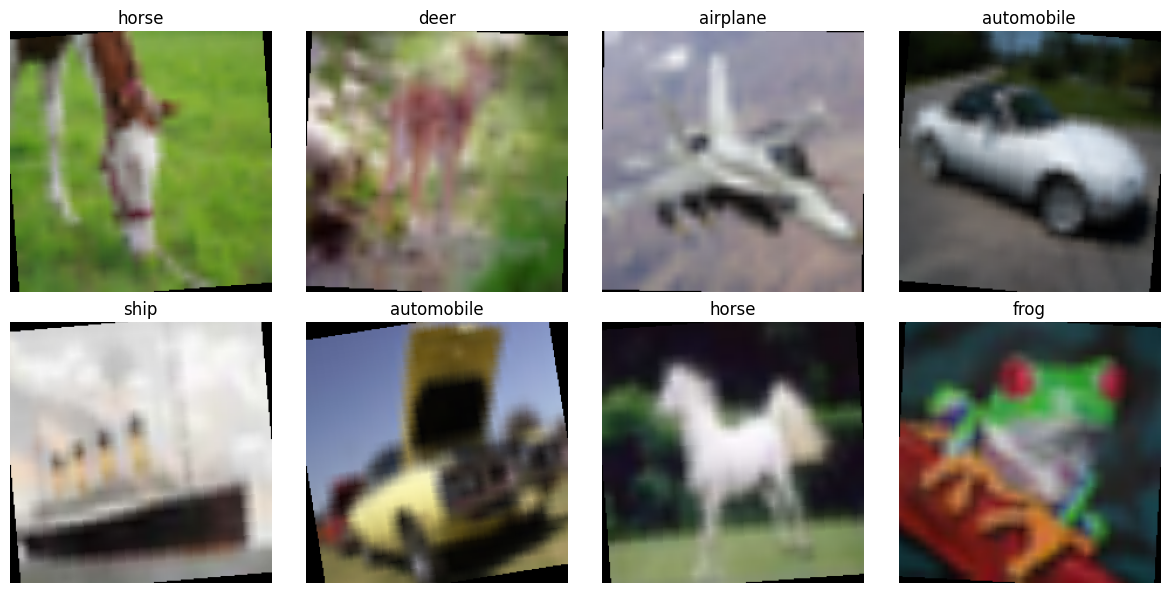

In [7]:
def show_batch(images_tensor, labels_tensor, count=8):
    mean = torch.tensor(imagenet_mean).view(3, 1, 1)
    std = torch.tensor(imagenet_std).view(3, 1, 1)
    count = min(count, len(images_tensor))
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for i, ax in enumerate(axes.flat):
        if i >= count:
            ax.axis("off")
            continue
        image = images_tensor[i].cpu() * std + mean
        image = image.clamp(0, 1).permute(1, 2, 0).numpy()
        ax.imshow(image)
        ax.set_title(class_names[int(labels_tensor[i])])
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_batch(images, labels)

## 8. Build pretrained EfficientNet-B0

This uses the current torchvision `weights` API (rather than the deprecated `pretrained=True` argument). The final classifier layer is replaced with a 10-class output layer.

We first freeze the feature extractor and train the new classifier. Later, we unfreeze the final feature blocks for fine-tuning.

In [8]:
model = models.efficientnet_b0(weights=weights)

# Freeze all pretrained feature extractor parameters initially.
for parameter in model.features.parameters():
    parameter.requires_grad = False

in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, NUM_CLASSES)
model = model.to(DEVICE)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())

print("Architecture: EfficientNet-B0")
print("Output classes:", NUM_CLASSES)
print(f"Trainable parameters: {trainable_params:,}")
print(f"Total parameters: {total_params:,}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 156MB/s]


Architecture: EfficientNet-B0
Output classes: 10
Trainable parameters: 12,810
Total parameters: 4,020,358


## 9. Training and evaluation functions

Mixed-precision training is enabled automatically on CUDA to reduce memory use and improve throughput on supported GPUs. CPU runs use normal precision.

In [9]:
USE_AMP = DEVICE.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
criterion = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for batch_images, batch_labels in loader:
        batch_images = batch_images.to(DEVICE, non_blocking=True)
        batch_labels = batch_labels.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.amp.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                logits = model(batch_images)
                loss = criterion(logits, batch_labels)

            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        batch_size = batch_labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(dim=1) == batch_labels).sum().item()
        total_examples += batch_size

    return {
        "loss": total_loss / max(total_examples, 1),
        "accuracy": total_correct / max(total_examples, 1),
    }

print("Training and evaluation functions ready.")

Training and evaluation functions ready.


## 10. Train classifier head, then fine-tune final feature blocks

The first phase trains only the newly initialized classifier. The second phase unfreezes the last two EfficientNet feature stages and uses a smaller learning rate for pretrained parameters.

The best checkpoint is selected using validation accuracy. Training can take time on a T4 GPU.

In [10]:
history = {
    "train_loss": [], "train_accuracy": [],
    "val_loss": [], "val_accuracy": [],
}
best_val_accuracy = -1.0
best_state = None

def save_checkpoint(path, epoch, val_accuracy):
    torch.save({
        "epoch": epoch,
        "model_name": "efficientnet_b0",
        "num_classes": NUM_CLASSES,
        "class_names": class_names,
        "image_size": IMAGE_SIZE,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_val_accuracy": best_val_accuracy,
        "history": history,
    }, path)

for epoch in range(EPOCHS):
    # After the head-only phase, unfreeze the last two feature stages once.
    if epoch == INITIAL_HEAD_EPOCHS:
        for stage in list(model.features.children())[-2:]:
            for parameter in stage.parameters():
                parameter.requires_grad = True

        optimizer = torch.optim.AdamW([
            {
                "params": [p for p in model.features.parameters() if p.requires_grad],
                "lr": LEARNING_RATE_FINETUNE,
            },
            {
                "params": model.classifier.parameters(),
                "lr": LEARNING_RATE_HEAD,
            },
        ], weight_decay=WEIGHT_DECAY)
        print("\nUnfroze final EfficientNet feature stages for fine-tuning.")

    if epoch == 0:
        optimizer = torch.optim.AdamW(
            model.classifier.parameters(),
            lr=LEARNING_RATE_HEAD,
            weight_decay=WEIGHT_DECAY,
        )

    start_time = time.time()
    train_metrics = run_epoch(model, train_loader, optimizer=optimizer)
    val_metrics = run_epoch(model, val_loader, optimizer=None)
    elapsed = time.time() - start_time

    history["train_loss"].append(train_metrics["loss"])
    history["train_accuracy"].append(train_metrics["accuracy"])
    history["val_loss"].append(val_metrics["loss"])
    history["val_accuracy"].append(val_metrics["accuracy"])

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"train loss {train_metrics['loss']:.4f} | "
        f"train acc {train_metrics['accuracy']:.4f} | "
        f"val loss {val_metrics['loss']:.4f} | "
        f"val acc {val_metrics['accuracy']:.4f} | "
        f"{elapsed:.1f}s"
    )

    if val_metrics["accuracy"] > best_val_accuracy:
        best_val_accuracy = val_metrics["accuracy"]
        best_state = deepcopy(model.state_dict())
        save_checkpoint(BEST_CHECKPOINT_PATH, epoch + 1, best_val_accuracy)
        print(f"  Saved new best checkpoint: {BEST_CHECKPOINT_PATH.name}")

    save_checkpoint(LAST_CHECKPOINT_PATH, epoch + 1, best_val_accuracy)

if best_state is not None:
    model.load_state_dict(best_state)

print("\nTraining complete.")
print(f"Best validation accuracy: {best_val_accuracy:.4f}")
print("Best checkpoint:", BEST_CHECKPOINT_PATH)

Epoch 01/10 | train loss 1.5951 | train acc 0.5632 | val loss 1.1596 | val acc 0.7156 | 113.2s
  Saved new best checkpoint: efficientnet_b0_cifar10_best.pth
Epoch 02/10 | train loss 1.1136 | train acc 0.6702 | val loss 0.8782 | val acc 0.7606 | 109.7s
  Saved new best checkpoint: efficientnet_b0_cifar10_best.pth
Epoch 03/10 | train loss 0.9885 | train acc 0.6860 | val loss 0.7930 | val acc 0.7666 | 108.1s
  Saved new best checkpoint: efficientnet_b0_cifar10_best.pth

Unfroze final EfficientNet feature stages for fine-tuning.
Epoch 04/10 | train loss 0.8364 | train acc 0.7230 | val loss 0.6064 | val acc 0.8090 | 110.9s
  Saved new best checkpoint: efficientnet_b0_cifar10_best.pth
Epoch 05/10 | train loss 0.7172 | train acc 0.7561 | val loss 0.5172 | val acc 0.8270 | 111.7s
  Saved new best checkpoint: efficientnet_b0_cifar10_best.pth
Epoch 06/10 | train loss 0.6655 | train acc 0.7709 | val loss 0.4824 | val acc 0.8392 | 114.2s
  Saved new best checkpoint: efficientnet_b0_cifar10_best.pt

## 11. Plot training history

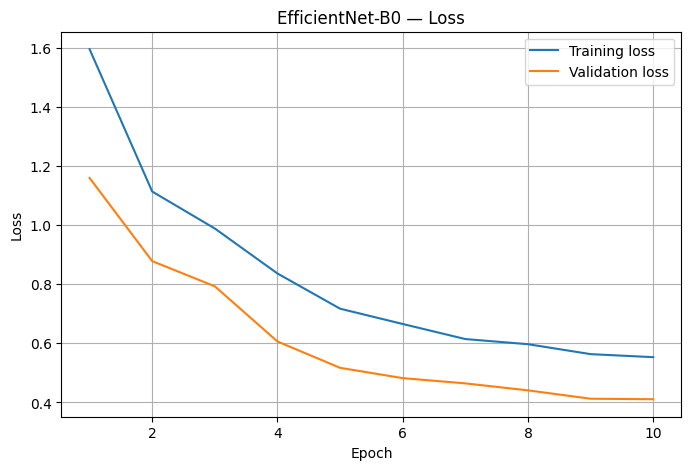

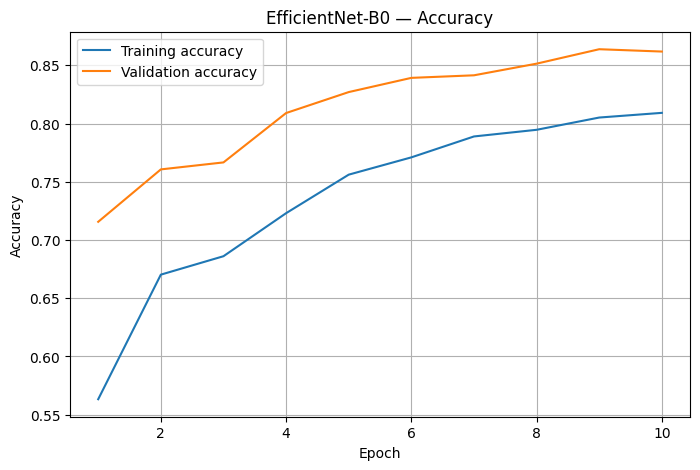

In [11]:
epochs_range = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history["train_loss"], label="Training loss")
plt.plot(epochs_range, history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("EfficientNet-B0 — Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history["train_accuracy"], label="Training accuracy")
plt.plot(epochs_range, history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("EfficientNet-B0 — Accuracy")
plt.legend()
plt.grid(True)
plt.show()

## 12. Evaluate on the official CIFAR-10 test set

The official test set was not used for training or model selection. This is the final held-out evaluation.

In [12]:
best_checkpoint = torch.load(BEST_CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(best_checkpoint["model_state_dict"])
model.eval()

test_metrics = run_epoch(model, test_loader, optimizer=None)

print("========== TEST RESULTS ==========")
print(f"Test loss: {test_metrics['loss']:.4f}")
print(f"Test accuracy: {test_metrics['accuracy']:.4f}")
print(f"Test accuracy (%): {test_metrics['accuracy'] * 100:.2f}%")

========== TEST RESULTS ==========
Test loss: 0.4181
Test accuracy: 0.8571
Test accuracy (%): 85.71%


## 13. Per-class accuracy and confusion matrix

              precision    recall  f1-score   support

    airplane     0.8776    0.8600    0.8687      1000
  automobile     0.9350    0.9350    0.9350      1000
        bird     0.7915    0.8160    0.8035      1000
         cat     0.7950    0.6980    0.7433      1000
        deer     0.8425    0.8240    0.8332      1000
         dog     0.8018    0.8170    0.8093      1000
        frog     0.8398    0.9120    0.8744      1000
       horse     0.8768    0.8970    0.8868      1000
        ship     0.9113    0.8840    0.8975      1000
       truck     0.8966    0.9280    0.9120      1000

    accuracy                         0.8571     10000
   macro avg     0.8568    0.8571    0.8564     10000
weighted avg     0.8568    0.8571    0.8564     10000



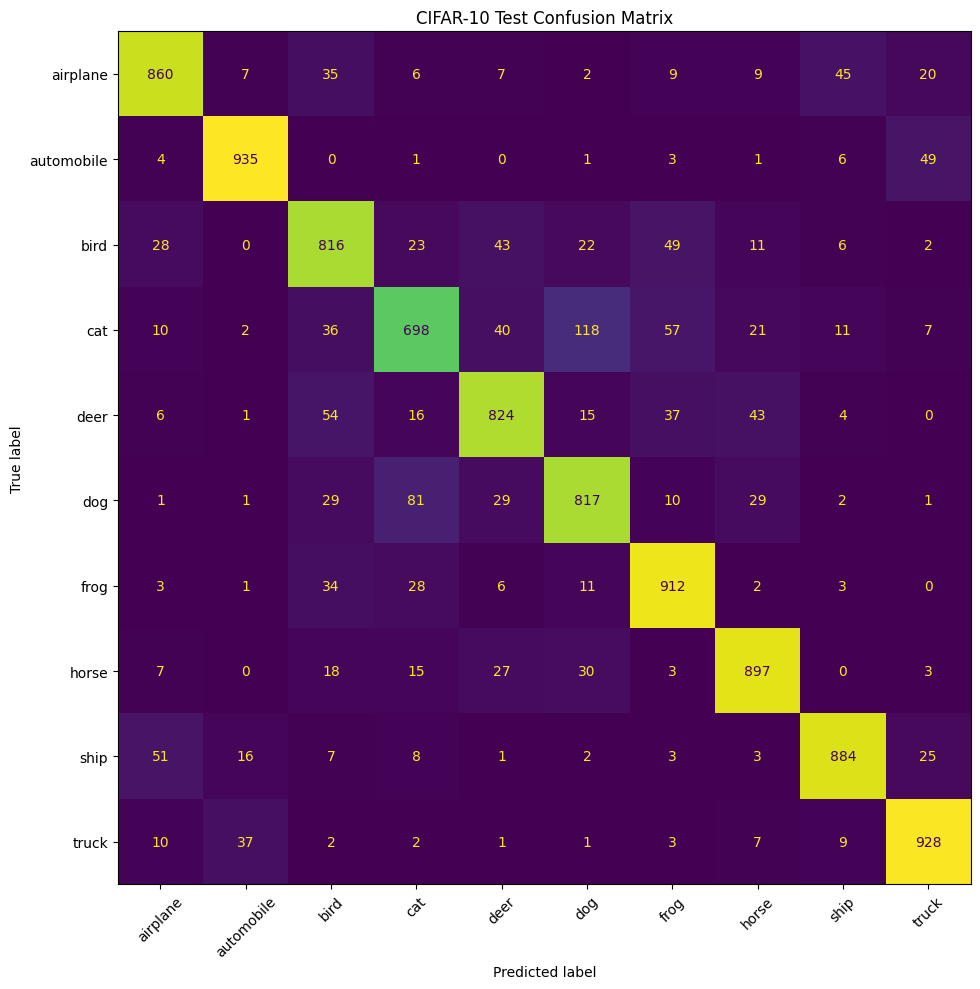

In [13]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

all_predictions = []
all_targets = []

model.eval()
with torch.no_grad():
    for batch_images, batch_labels in test_loader:
        batch_images = batch_images.to(DEVICE, non_blocking=True)
        with torch.amp.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            logits = model(batch_images)
        predictions = logits.argmax(dim=1).cpu().numpy()
        all_predictions.extend(predictions.tolist())
        all_targets.extend(batch_labels.numpy().tolist())

print(classification_report(
    all_targets,
    all_predictions,
    target_names=class_names,
    digits=4,
))

cm = confusion_matrix(all_targets, all_predictions)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(10, 10))
display.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("CIFAR-10 Test Confusion Matrix")
plt.tight_layout()
plt.show()

## 14. Save final training report

The report is stored alongside the model checkpoints. Do not commit large `.pth` checkpoint files to Git unless the repository intentionally uses Git LFS or another artifact store.

In [14]:
report = {
    "project": "Project Aura 2.0",
    "notebook": "03_model_training",
    "dataset": "CIFAR-10",
    "architecture": "EfficientNet-B0",
    "pretrained": True,
    "num_classes": NUM_CLASSES,
    "class_names": class_names,
    "image_size": IMAGE_SIZE,
    "epochs_completed": len(history["train_loss"]),
    "best_validation_accuracy": float(best_val_accuracy),
    "test_loss": float(test_metrics["loss"]),
    "test_accuracy": float(test_metrics["accuracy"]),
    "device": str(DEVICE),
    "gpu_name": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
    "history": history,
}

REPORT_PATH = CHECKPOINT_DIR / "efficientnet_b0_cifar10_report.json"
REPORT_PATH.write_text(json.dumps(report, indent=2))

print("Report saved:", REPORT_PATH)
print("Best model saved:", BEST_CHECKPOINT_PATH)
print("Last model saved:", LAST_CHECKPOINT_PATH)

Report saved: /content/project-aura-verified/checkpoints/efficientnet_b0_cifar10_report.json
Best model saved: /content/project-aura-verified/checkpoints/efficientnet_b0_cifar10_best.pth
Last model saved: /content/project-aura-verified/checkpoints/efficientnet_b0_cifar10_last.pth


## 15. Final validation

This validates the saved artifacts and confirms the trained model returns ten class scores for a sample batch.

In [15]:
assert BEST_CHECKPOINT_PATH.is_file(), "Best checkpoint missing."
assert LAST_CHECKPOINT_PATH.is_file(), "Last checkpoint missing."
assert REPORT_PATH.is_file(), "Training report missing."

sample_images, sample_labels = next(iter(test_loader))
sample_images = sample_images[:4].to(DEVICE)

model.eval()
with torch.no_grad():
    with torch.amp.autocast(device_type=DEVICE.type, enabled=USE_AMP):
        sample_logits = model(sample_images)
    sample_probabilities = torch.softmax(sample_logits.float(), dim=1)

assert sample_logits.shape == (4, NUM_CLASSES)
assert torch.isfinite(sample_probabilities).all()

print("Best checkpoint exists:", BEST_CHECKPOINT_PATH.exists())
print("Last checkpoint exists:", LAST_CHECKPOINT_PATH.exists())
print("Training report exists:", REPORT_PATH.exists())
print("Sample prediction shape:", tuple(sample_probabilities.shape))
print("\nNOTEBOOK 03 TRAINING PIPELINE VALIDATION PASSED")

Best checkpoint exists: True
Last checkpoint exists: True
Training report exists: True
Sample prediction shape: (4, 10)

NOTEBOOK 03 TRAINING PIPELINE VALIDATION PASSED


## 16. Optional: copy artifacts to Google Drive

Colab local storage is temporary. If you want to keep the trained model after the runtime ends, mount Google Drive and copy the checkpoint and report. This cell is optional and requires your explicit interaction with the Drive authorization prompt.

In [16]:
# OPTIONAL — run only if you want to persist model artifacts in Google Drive.
#
# from google.colab import drive
# drive.mount("/content/drive")
#
# DRIVE_ARTIFACT_DIR = Path("/content/drive/MyDrive/ProjectAura/checkpoints")
# DRIVE_ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
#
# import shutil
# for artifact in [BEST_CHECKPOINT_PATH, LAST_CHECKPOINT_PATH, REPORT_PATH]:
#     shutil.copy2(artifact, DRIVE_ARTIFACT_DIR / artifact.name)
#
# print("Artifacts copied to:", DRIVE_ARTIFACT_DIR)